In [14]:
#Cell 1: Load and split
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
import lightgbm as lgb
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

df = pd.read_csv("../data/processed/pjme_clean.csv", index_col="Datetime", parse_dates=True)
y = df["load_mw"].asfreq("h")

TRAIN_END = "2016-12-31 23:00"
VAL_END = "2017-12-31 23:00"

print("Train: ", y.index.min(), "->", TRAIN_END)
print("Val:   ", "2017-01-01", "->", VAL_END)
print("Test:  ", "2018-01-01", "->", y.index.max())

Train:  2002-01-01 01:00:00 -> 2016-12-31 23:00
Val:    2017-01-01 -> 2017-12-31 23:00
Test:   2018-01-01 -> 2018-08-03 00:00:00


In [15]:
#Cell 2: Metrics and baselines
def metrics(y_true, y_pred):
    err = y_true - y_pred
    return {
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "MAPE_%": np.mean(np.abs(err / y_true)) * 100,
    }

y_test = y["2018-01-01":]

preds = pd.DataFrame({"actual": y_test})
preds["naive_24"] = y.shift(24).loc[y_test.index]    # same hour yesterday
preds["naive_168"] = y.shift(168).loc[y_test.index]  # same hour last week

results = {m: metrics(preds["actual"], preds[m]) for m in ["naive_24", "naive_168"]}
pd.DataFrame(results).T.round(2)

,MAE,RMSE,MAPE_%
naive_24,2530.47,3397.10,7.90
naive_168,3621.49,4947.85,11.11


In [16]:
#Cell 3: Feature engineering
us_hol = holidays.US(years=range(2002, 2019))
hol_dates = pd.to_datetime(list(us_hol.keys()))

def make_features(s):
    d = pd.DataFrame({"load_mw": s})

    # Lags (all >= 24h, so they are known at forecast time)
    for lag in [24, 48, 72, 168, 336]:
        d[f"lag_{lag}"] = s.shift(lag)

    # Rolling stats, shifted by 24h to avoid leakage
    past = s.shift(24)
    d["roll_mean_24"] = past.rolling(24).mean()
    d["roll_mean_168"] = past.rolling(168).mean()
    d["roll_std_24"] = past.rolling(24).std()

    # Calendar
    d["hour"] = d.index.hour
    d["dayofweek"] = d.index.dayofweek
    d["month"] = d.index.month
    d["is_weekend"] = (d["dayofweek"] >= 5).astype(int)
    d["is_holiday"] = d.index.normalize().isin(hol_dates).astype(int)

    # Cyclical encodings
    d["hour_sin"] = np.sin(2 * np.pi * d["hour"] / 24)
    d["hour_cos"] = np.cos(2 * np.pi * d["hour"] / 24)
    d["doy_sin"] = np.sin(2 * np.pi * d.index.dayofyear / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * d.index.dayofyear / 365.25)

    return d.dropna()

feat = make_features(y)
FEATURES = [c for c in feat.columns if c != "load_mw"]

train = feat[:TRAIN_END]
val = feat["2017-01-01":VAL_END]
test = feat["2018-01-01":]

print(len(train), len(val), len(test))
print(FEATURES)

131159 8760 5137
['lag_24', 'lag_48', 'lag_72', 'lag_168', 'lag_336', 'roll_mean_24', 'roll_mean_168', 'roll_std_24', 'hour', 'dayofweek', 'month', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']


In [17]:
#Cell 4: LightGBM
X_train, y_train = train[FEATURES], train["load_mw"]
X_val, y_val = val[FEATURES], val["load_mw"]
X_test, y_test_f = test[FEATURES], test["load_mw"]

params = dict(
    learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, verbose=-1,
)

# 1) Tune the number of trees on validation (early stopping)
model = lgb.LGBMRegressor(n_estimators=3000, **params)
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="l1",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)],
)
best_n = model.best_iteration_
print("Best number of trees:", best_n)

# 2) Refit on train + validation with that number of trees
final = lgb.LGBMRegressor(n_estimators=best_n, **params)
final.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

preds["lightgbm"] = pd.Series(final.predict(X_test), index=X_test.index)
results["lightgbm"] = metrics(preds["actual"], preds["lightgbm"])
pd.DataFrame(results).T.round(2)

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[691]	valid_0's l1: 1741.55	valid_0's l2: 5.42469e+06
Best number of trees: 691


,MAE,RMSE,MAPE_%
naive_24,2530.47,3397.10,7.90
naive_168,3621.49,4947.85,11.11
lightgbm,2016.29,2700.24,6.24


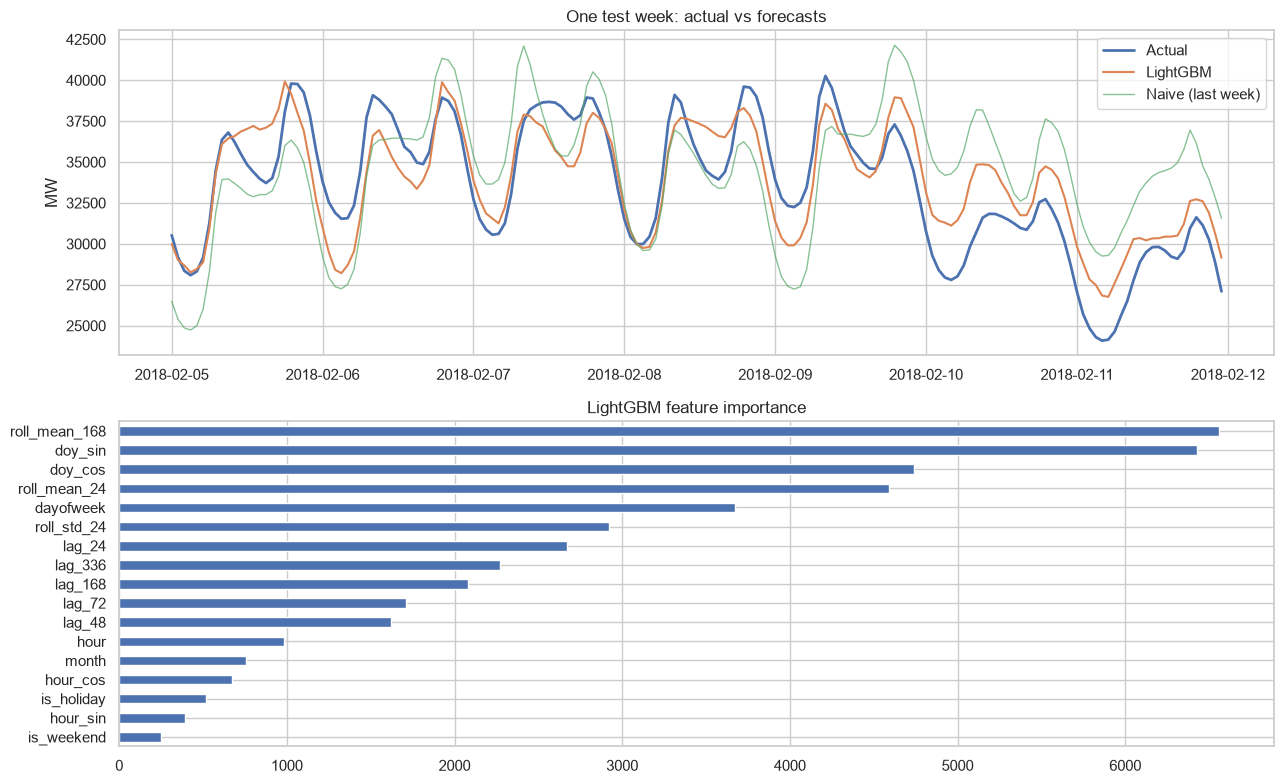

In [18]:
#Cell 5: Plots
fig, ax = plt.subplots(2, 1, figsize=(13, 8))

week = preds["2018-02-05":"2018-02-11"]
ax[0].plot(week["actual"], label="Actual", lw=2)
ax[0].plot(week["lightgbm"], label="LightGBM", lw=1.5)
ax[0].plot(week["naive_168"], label="Naive (last week)", lw=1, alpha=0.7)
ax[0].set_title("One test week: actual vs forecasts")
ax[0].set_ylabel("MW")
ax[0].legend()

imp = pd.Series(final.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", ax=ax[1], title="LightGBM feature importance")

plt.tight_layout()
plt.savefig("../reports/figures/06_lightgbm_results.png", dpi=150)
plt.show()

In [19]:
#Cell 6: Where does the model fail?
err = (preds["actual"] - preds["lightgbm"]).abs()
print("MAE by hour of day:")
print(err.groupby(err.index.hour).mean().round(0).to_string())

print("\nWorst 5 days (mean absolute error):")
print(err.resample("D").mean().sort_values(ascending=False).head(5).round(0))

MAE by hour of day:
Datetime
0     1868.0
1     1810.0
2     1743.0
3     1705.0
4     1678.0
5     1672.0
6     1766.0
7     1824.0
8     1780.0
9     1637.0
10    1584.0
11    1690.0
12    1845.0
13    2089.0
14    2265.0
15    2410.0
16    2494.0
17    2592.0
18    2615.0
19    2526.0
20    2409.0
21    2249.0
22    2139.0
23    2002.0

Worst 5 days (mean absolute error):
Datetime
2018-01-05    5804.0
2018-01-06    5561.0
2018-07-07    5199.0
2018-06-03    4850.0
2018-06-11    4736.0
dtype: float64


In [20]:
#Cell 7: SARIMA (slower, and evaluated on fewer days)
# Cell 7: SARIMA
N_DAYS = 30   # smaller = faster; raise to 60 if it runs quickly

fit_window = y["2017-12-04":"2017-12-31 23:00"]   # 28 days before the test period
sarima = SARIMAX(
    fit_window, order=(1, 0, 1), seasonal_order=(1, 1, 1, 24),
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)

days = pd.date_range("2018-01-01", periods=N_DAYS, freq="D")
sarima_fc = []
res = sarima
for day in days:
    fc = res.forecast(24)                      # forecast the next 24 hours
    sarima_fc.append(fc)
    actual_day = y[day:day + pd.Timedelta(hours=23)]
    res = res.append(actual_day, refit=False)  # roll forward without refitting

sarima_pred = pd.concat(sarima_fc)
sarima_pred.name = "sarima"

# Compare all models on exactly the same days
common = preds.loc[sarima_pred.index].copy()
common["sarima"] = sarima_pred
comp = {m: metrics(common["actual"], common[m])
        for m in ["naive_24", "naive_168", "sarima", "lightgbm"]}
print(f"Comparison on the first {N_DAYS} test days:")
print(pd.DataFrame(comp).T.round(2))

Comparison on the first 30 test days:
               MAE     RMSE  MAPE_%
naive_24   2734.96  3359.40    7.97
naive_168  5333.74  6583.01   15.85
sarima     1813.08  2367.83    5.12
lightgbm   2657.66  3319.22    7.51


In [21]:
#Cell 8: Save predictions
#Cell 8: Save predictions
preds.to_csv("../data/processed/test_predictions.csv")
# sarima_pred.to_csv("../data/processed/sarima_predictions.csv")  # still missing
final.booster_.save_model("../models/lightgbm.txt")

In [22]:
# See what prediction-related variables currently exist
[name for name in dir() if "pred" in name.lower() or "sarima" in name.lower() or "forecast" in name.lower()]

# Or just check specific candidates
print("sarima_pred" in dir())
print("preds" in dir())
print("final" in dir())

True
True
True


In [23]:
print("preds" in dir())
print("final" in dir())
print("sarima_pred" in dir())

# Show all variables that look related to predictions or models
related = [name for name in dir() if any(k in name.lower() for k in ["pred", "forecast", "sarima", "lgb", "lightgbm", "model"])]
print("Related variables:", related)

True
True
True
Related variables: ['SARIMAX', 'lgb', 'model', 'preds', 'sarima', 'sarima_fc', 'sarima_pred']


In [24]:
final.booster_.save_model("../models/lightgbm.txt")

In [25]:
# Cell 4b: LightGBM v2 with midnight-anchored features
def anchored(ser):
    a = ser[ser.index.hour == 23].copy()
    a.index = a.index.normalize() + pd.Timedelta(days=1)
    return a.reindex(feat.index.normalize()).values

feat2 = feat.copy()
feat2["anchor_load"] = anchored(y)
feat2["anchor_lag1"] = anchored(y.shift(1))
feat2["anchor_lag2"] = anchored(y.shift(2))
feat2["anchor_mean_24"] = anchored(y.rolling(24).mean())
feat2["anchor_mean_168"] = anchored(y.rolling(168).mean())
feat2 = feat2.dropna()

FEATURES2 = [c for c in feat2.columns if c != "load_mw"]
tr2, va2, te2 = feat2[:TRAIN_END], feat2["2017-01-01":VAL_END], feat2["2018-01-01":]

m2 = lgb.LGBMRegressor(n_estimators=3000, **params)
m2.fit(tr2[FEATURES2], tr2["load_mw"],
       eval_set=[(va2[FEATURES2], va2["load_mw"])], eval_metric="l1",
       callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)])

final2 = lgb.LGBMRegressor(n_estimators=m2.best_iteration_, **params)
final2.fit(pd.concat([tr2[FEATURES2], va2[FEATURES2]]),
           pd.concat([tr2["load_mw"], va2["load_mw"]]))
preds["lightgbm_v2"] = pd.Series(final2.predict(te2[FEATURES2]), index=te2.index)

lstm = pd.read_csv("../data/processed/lstm_predictions.csv", index_col=0, parse_dates=True).iloc[:, 0]
common = preds.loc[lstm.index].copy()
common["lstm"] = lstm
res = {m: metrics(common["actual"], common[m])
       for m in ["naive_24", "lightgbm", "lightgbm_v2", "lstm"]}
print(pd.DataFrame(res).T.round(2))

preds.to_csv("../data/processed/test_predictions.csv")
final2.booster_.save_model("../models/lightgbm_v2.txt")

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[2606]	valid_0's l1: 1188.78	valid_0's l2: 3.00984e+06
                 MAE     RMSE  MAPE_%
naive_24     2530.64  3397.36    7.91
lightgbm     2016.42  2700.44    6.24
lightgbm_v2  1510.86  2180.70    4.52
lstm         1514.63  2144.81    4.59


In [26]:
sarima_pred.to_csv("../data/processed/sarima_predictions.csv")